In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import DBSCAN
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

Full dataset loaded: 284,807 rows, 30 numeric features.
Ground-Truth Outliers: 492 rows (0.1727%)


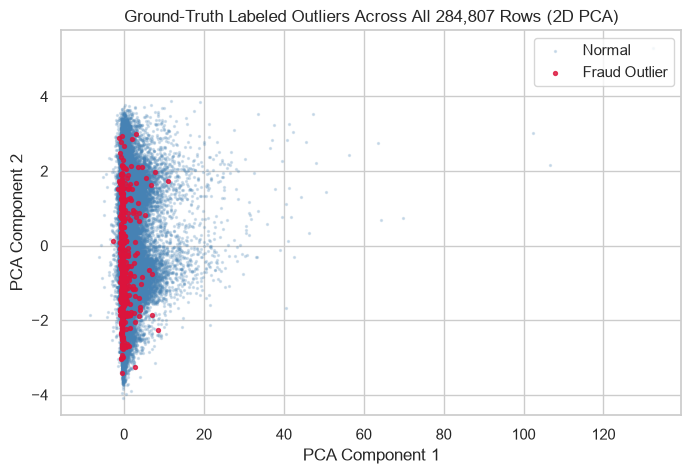

In [3]:
csv_path = "./data/creditcard.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"'{csv_path}' not found. Run 'uv run python download_dataset.py' first."
    )

# Load the ENTIRE dataset (all 284,807 rows)
df = pd.read_csv(csv_path)

# Separate numeric features (30 columns: Time, V1-V28, Amount) and ground-truth label (Class)
X = df.drop(columns=["Class"])
y_true = df["Class"].astype(int).to_numpy()  # 1 = True Outlier (Fraud), 0 = Normal

# Standardize all 30 features and use float32 to cut RAM usage in half
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

# Compute 2D PCA projection for visualization and fast spatial indexing
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled).astype(np.float32)

# True outlier ratio across all 284,807 rows (492 / 284807 = 0.001727)
contamination_rate = float(y_true.mean())

# DataFrame to store binary predictions (1 = Outlier, 0 = Inlier) for all 284,807 rows
outliers_df = pd.DataFrame(index=df.index)

print(f"Full dataset loaded: {X_scaled.shape[0]:,} rows, {X_scaled.shape[1]} numeric features.")
print(f"Ground-Truth Outliers: {y_true.sum()} rows ({contamination_rate * 100:.4f}%)")

# Visualize Ground-Truth Outliers in PCA Space
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[y_true == 0, 0], X_pca[y_true == 0, 1], c="steelblue", s=2, alpha=0.2, label="Normal")
plt.scatter(X_pca[y_true == 1, 0], X_pca[y_true == 1, 1], c="crimson", s=8, alpha=0.8, label="Fraud Outlier")
plt.title("Ground-Truth Labeled Outliers Across All 284,807 Rows (2D PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(loc="upper right")
plt.show()

Mahalanobis Threshold (Chi2): 57.71
Mahalanobis Outliers Detected: 14,333 (5.033%)
F1-Score vs Ground Truth: 0.0581


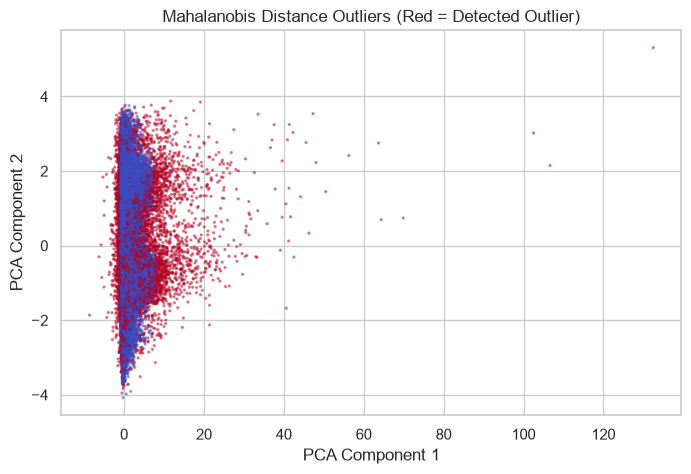

In [4]:
# Compute mean vector and inverse covariance matrix
mean_vec = np.mean(X_scaled, axis=0)
cov_matrix = np.cov(X_scaled, rowvar=False)
inv_cov_matrix = np.linalg.pinv(cov_matrix)

# Compute squared Mahalanobis distance for all 284,807 samples
diff = X_scaled - mean_vec
md_squared = np.sum(np.dot(diff, inv_cov_matrix) * diff, axis=1)

# Set Chi-Square threshold matching the true contamination percentile (99.83%)
dof = X_scaled.shape[1]
threshold_md = chi2.ppf(1.0 - contamination_rate, dof)

outliers_df["Mahalanobis"] = (md_squared > threshold_md).astype(np.int8)

n_md = outliers_df["Mahalanobis"].sum()
print(f"Mahalanobis Threshold (Chi2): {threshold_md:.2f}")
print(f"Mahalanobis Outliers Detected: {n_md:,} ({n_md / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Mahalanobis']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Mahalanobis"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("Mahalanobis Distance Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Isolation Forest Outliers Detected: 492 (0.173%)
F1-Score vs Ground Truth: 0.2317


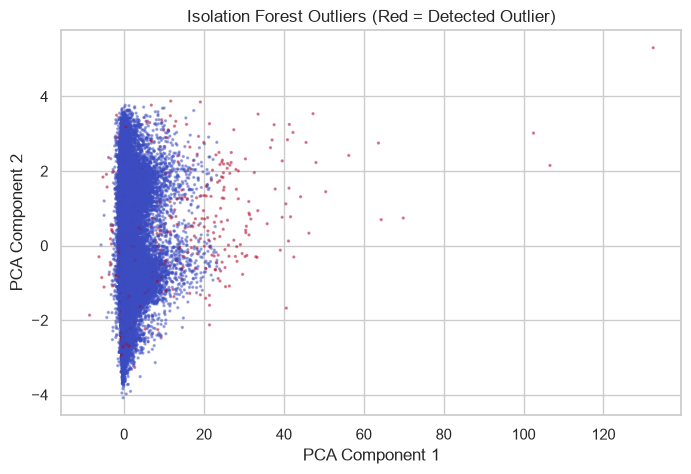

In [5]:
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=contamination_rate,
    random_state=42,
    n_jobs=-1
)

iso_preds = iso_forest.fit_predict(X_scaled)
outliers_df["Isolation_Forest"] = (iso_preds == -1).astype(np.int8)

n_iso = outliers_df["Isolation_Forest"].sum()
print(f"Isolation Forest Outliers Detected: {n_iso:,} ({n_iso / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Isolation_Forest']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Isolation_Forest"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("Isolation Forest Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

LOF Outliers Detected: 492 (0.173%)
F1-Score vs Ground Truth: 0.0224


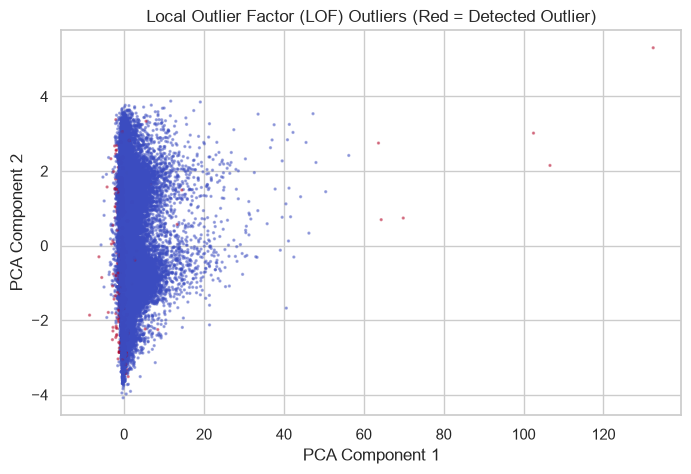

In [6]:
# Use top 5 PCA components with a KD-Tree so LOF finishes in seconds on 284,807 rows
X_pca5 = PCA(n_components=5, random_state=42).fit_transform(X_scaled).astype(np.float32)

lof = LocalOutlierFactor(
    n_neighbors=35,
    contamination=contamination_rate,
    algorithm="kd_tree",
    leaf_size=60,
    n_jobs=-1
)

lof_preds = lof.fit_predict(X_pca5)
outliers_df["LOF"] = (lof_preds == -1).astype(np.int8)

n_lof = outliers_df["LOF"].sum()
print(f"LOF Outliers Detected: {n_lof:,} ({n_lof / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['LOF']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["LOF"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("Local Outlier Factor (LOF) Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [7]:
# dbscan = DBSCAN(
#     eps=0.5,
#     min_samples=15,
#     algorithm="kd_tree",
#     leaf_size=60,
#     n_jobs=-1
# )

# dbscan_labels = dbscan.fit_predict(X_pca)

# # In DBSCAN, label -1 indicates noise/outliers
# outliers_df["DBSCAN"] = (dbscan_labels == -1).astype(np.int8)

# n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
# n_db = outliers_df["DBSCAN"].sum()
# print(f"DBSCAN Clusters Found: {n_clusters}")
# print(f"DBSCAN Outliers Detected: {n_db:,} ({n_db / len(df) * 100:.3f}%)")
# print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['DBSCAN']):.4f}")

# plt.figure(figsize=(8, 5))
# plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["DBSCAN"], cmap="coolwarm", s=2, alpha=0.4)
# plt.title("DBSCAN Outliers / Noise Points (Red = Detected Outlier)")
# plt.xlabel("PCA Component 1")
# plt.ylabel("PCA Component 2")
# plt.show()

code above crashed because of out of memory error after 20s

the code below uses methods to claculate it in an optimal way

DBSCAN Clusters Found: 3
DBSCAN Outliers Detected: 145 (0.051%)
F1-Score vs Ground Truth: 0.0000


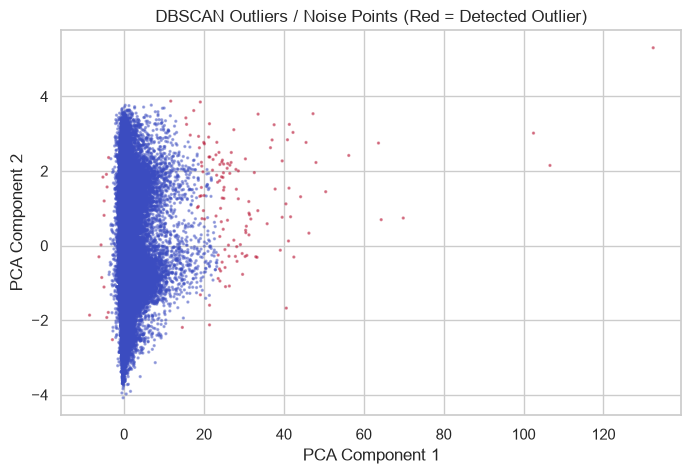

In [8]:
from sklearn.neighbors import NearestNeighbors

# Step 1: Compute distance to the 15th nearest neighbor (uses only ~17 MB of RAM)
min_samples = 15
eps_val = 0.8

nn = NearestNeighbors(n_neighbors=min_samples, algorithm="kd_tree", leaf_size=60, n_jobs=2)
nn.fit(X_pca)
k_distances, _ = nn.kneighbors(X_pca)

# Distance to the 15th neighbor for each of the 284,807 rows
dist_to_kth = k_distances[:, -1]

# Step 2: Points deep inside the dense normal center (k-distance <= 0.15) are guaranteed inliers (Cluster 0).
# Only run DBSCAN on the remaining sparse/boundary points (~3,000 - 6,000 rows) to avoid the 40 GB RAM explosion.
sparse_mask = dist_to_kth > 0.15

dbscan = DBSCAN(
    eps=eps_val,
    min_samples=min_samples,
    algorithm="kd_tree",
    n_jobs=2
)

# Initialize all 284,807 labels as Cluster 0 (Normal), then update sparse points with DBSCAN results
dbscan_labels = np.zeros(len(X_pca), dtype=np.int32)
sparse_labels = dbscan.fit_predict(X_pca[sparse_mask])

# Shift positive cluster IDs from sparse_labels by +1 so they don't collide with main Cluster 0, keep -1 as -1
dbscan_labels[sparse_mask] = np.where(sparse_labels == -1, -1, sparse_labels + 1)

# In DBSCAN, label -1 indicates noise/outliers
outliers_df["DBSCAN"] = (dbscan_labels == -1).astype(np.int8)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_db = outliers_df["DBSCAN"].sum()
print(f"DBSCAN Clusters Found: {n_clusters}")
print(f"DBSCAN Outliers Detected: {n_db:,} ({n_db / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['DBSCAN']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["DBSCAN"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("DBSCAN Outliers / Noise Points (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

One-Class SVM Outliers Detected: 492 (0.173%)
F1-Score vs Ground Truth: 0.0955


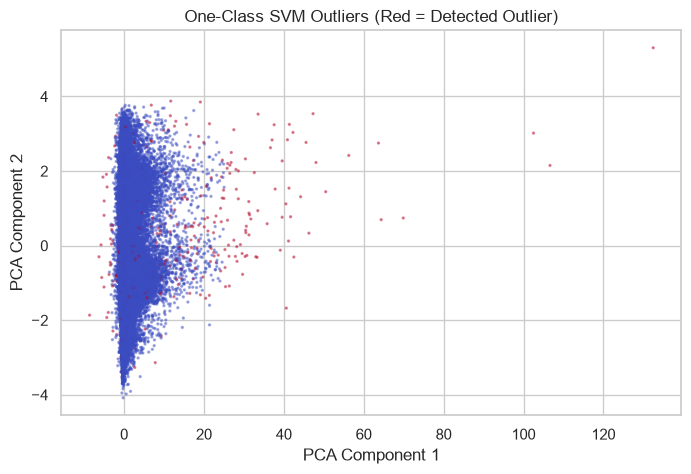

In [9]:
oc_svm = make_pipeline(
    Nystroem(kernel="rbf", gamma=1.0 / X_scaled.shape[1], n_components=150, random_state=42),
    SGDOneClassSVM(nu=contamination_rate, random_state=42)
)

svm_scores = oc_svm.fit(X_scaled).score_samples(X_scaled)
svm_threshold = np.percentile(svm_scores, contamination_rate * 100)
outliers_df["OneClass_SVM"] = (svm_scores < svm_threshold).astype(np.int8)

n_svm = outliers_df["OneClass_SVM"].sum()
print(f"One-Class SVM Outliers Detected: {n_svm:,} ({n_svm / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['OneClass_SVM']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["OneClass_SVM"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("One-Class SVM Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Z-Score (|Z| > 7.5) Outliers Detected: 3,868 (1.358%)
F1-Score vs Ground Truth: 0.1399


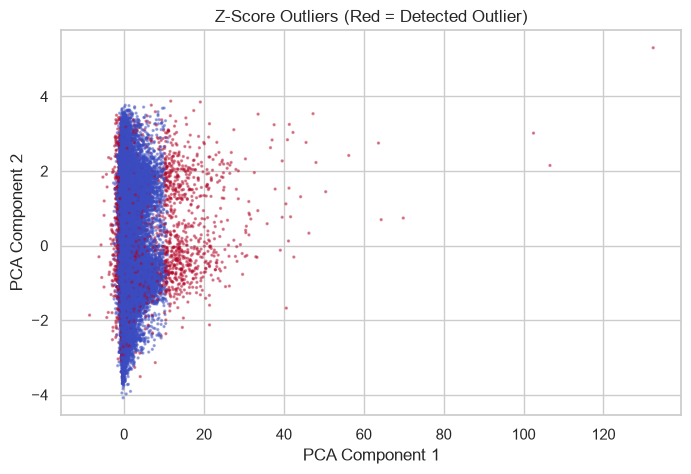

In [10]:
z_threshold = 7.5
outliers_df["Z_Score"] = (np.abs(X_scaled) > z_threshold).any(axis=1).astype(np.int8)

n_z = outliers_df["Z_Score"].sum()
print(f"Z-Score (|Z| > {z_threshold}) Outliers Detected: {n_z:,} ({n_z / len(df) * 100:.3f}%)")
print(f"F1-Score vs Ground Truth: {f1_score(y_true, outliers_df['Z_Score']):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Z_Score"], cmap="coolwarm", s=2, alpha=0.4)
plt.title("Z-Score Outliers (Red = Detected Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

=== QUANTITATIVE PERFORMANCE EVALUATION (ALL 284,807 ROWS) ===


,Detected_Outliers,True_Positives (TP),False_Positives (FP),False_Negatives (FN),Accuracy,Precision,Recall,F1-Score,ROC-AUC
Method,,,,,,,,,
Isolation_Forest,492,114,378,378,0.9973,0.2317,0.2317,0.2317,0.6152
Z_Score,3868,305,3563,187,0.9868,0.0789,0.6199,0.1399,0.8037
OneClass_SVM,492,47,445,445,0.9969,0.0955,0.0955,0.0955,0.5470
Mahalanobis,14333,431,13902,61,0.9510,0.0301,0.8760,0.0581,0.9136
LOF,492,11,481,481,0.9966,0.0224,0.0224,0.0224,0.5103
DBSCAN,145,0,145,492,0.9978,0.0000,0.0000,0.0000,0.4997


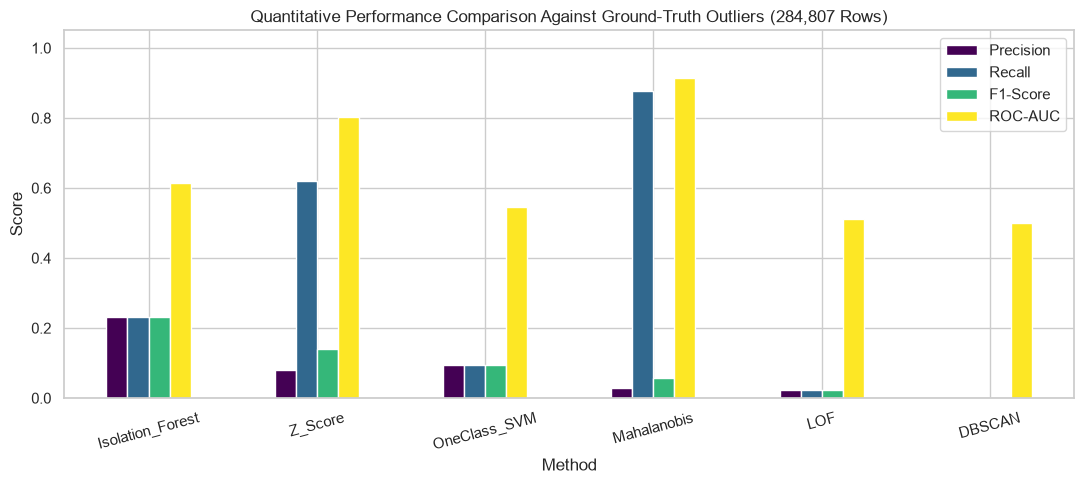

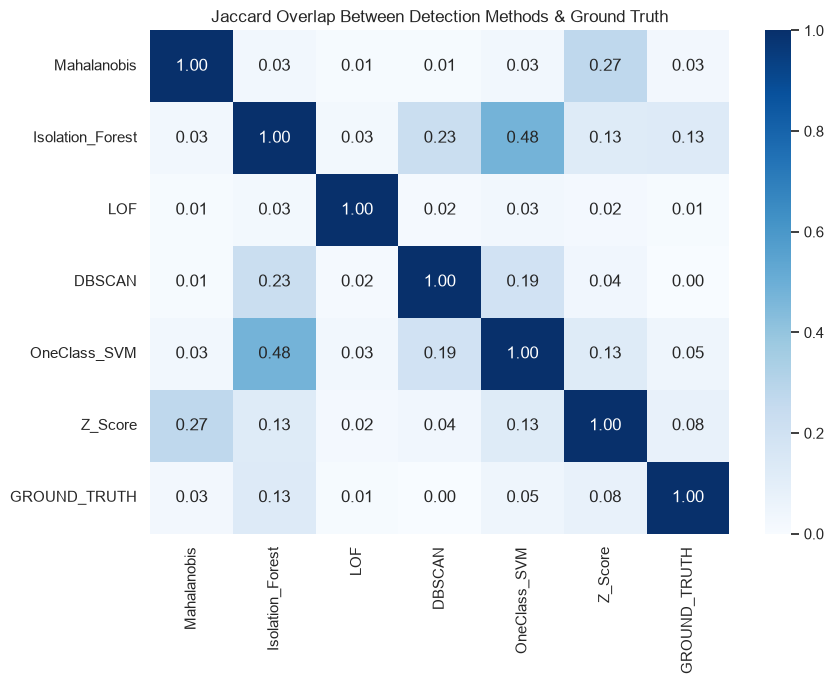

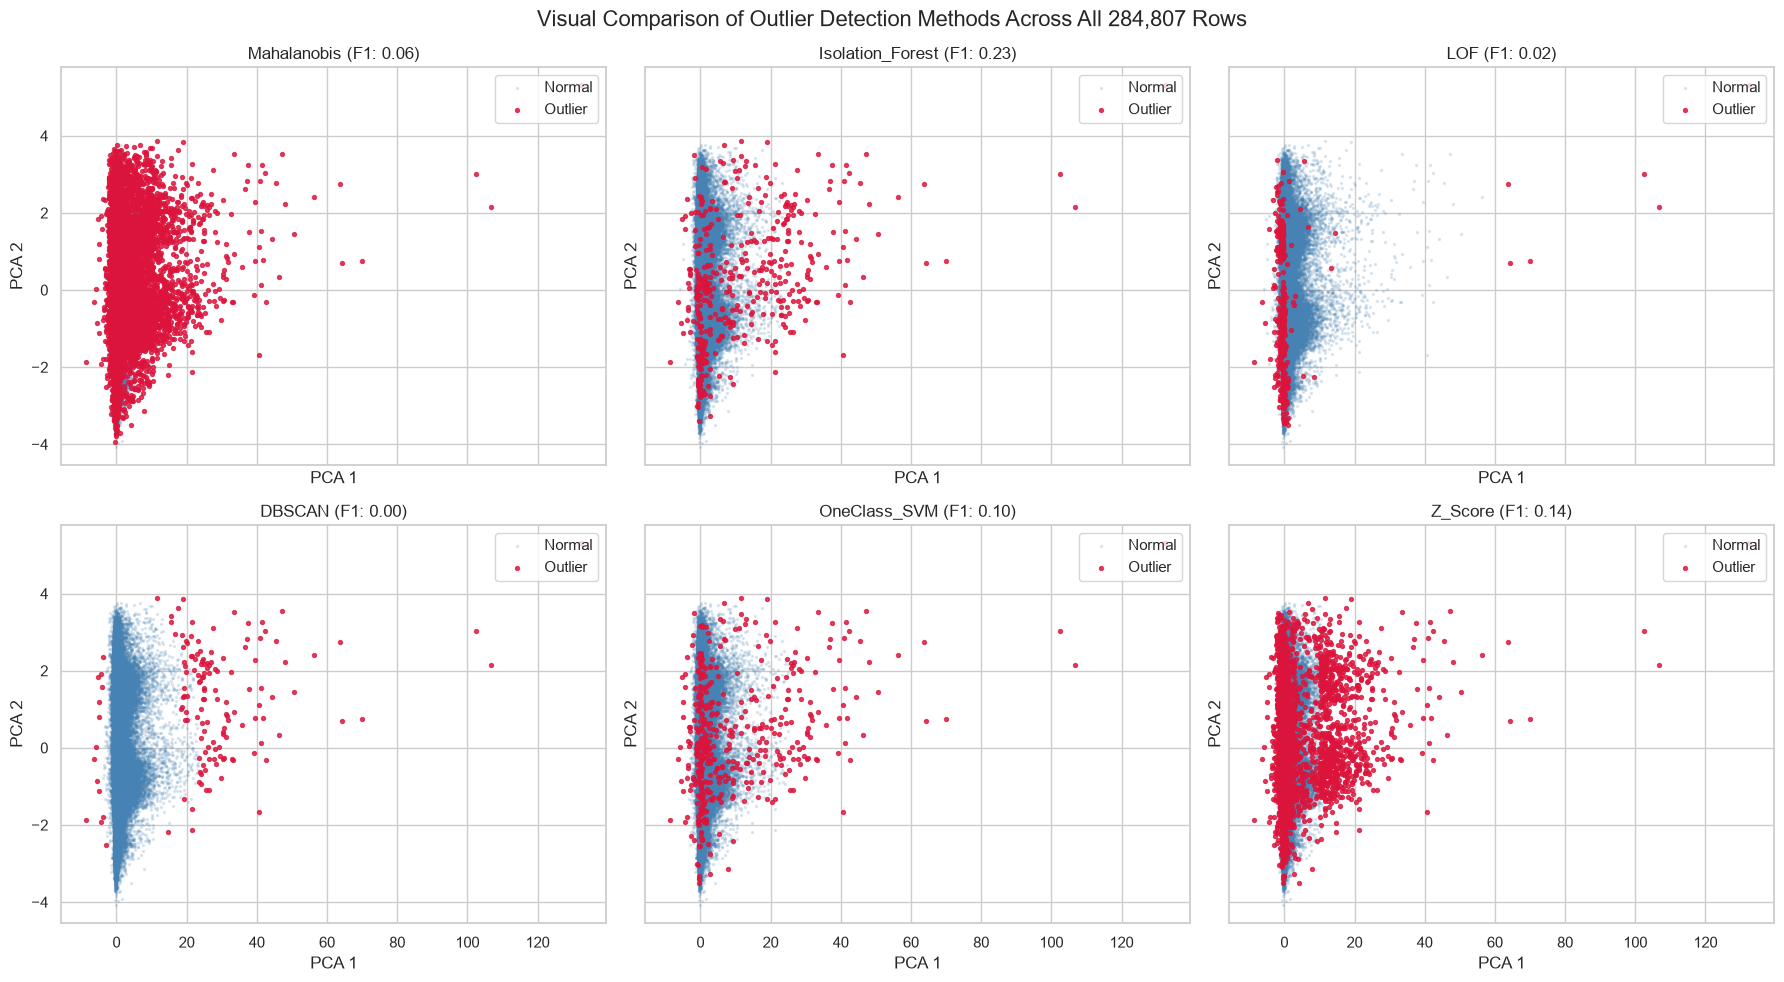

In [11]:
# 1. Quantitative Performance Against Real Ground-Truth Labels (y_true)
eval_rows = []
for method in outliers_df.columns:
    y_pred = outliers_df[method]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    eval_rows.append({
        "Method": method,
        "Detected_Outliers": int(y_pred.sum()),
        "True_Positives (TP)": int(tp),
        "False_Positives (FP)": int(fp),
        "False_Negatives (FN)": int(fn),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_pred)
    })

eval_df = pd.DataFrame(eval_rows).set_index("Method").sort_values(by="F1-Score", ascending=False)
print("=== QUANTITATIVE PERFORMANCE EVALUATION (ALL 284,807 ROWS) ===")
display(eval_df.round(4))

# 2. Bar Chart Comparing Precision, Recall, F1-Score, and ROC-AUC
eval_df[["Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), rot=15, colormap="viridis"
)
plt.title("Quantitative Performance Comparison Against Ground-Truth Outliers (284,807 Rows)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# 3. Pairwise Agreement Heatmap (Jaccard Similarity Including Ground Truth)
compare_df = outliers_df.copy()
compare_df["GROUND_TRUTH"] = y_true
cols = compare_df.columns
jaccard = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        inter = np.logical_and(compare_df[c1], compare_df[c2]).sum()
        union = np.logical_or(compare_df[c1], compare_df[c2]).sum()
        jaccard.loc[c1, c2] = inter / union if union > 0 else 0.0

plt.figure(figsize=(9, 7))
sns.heatmap(jaccard, annot=True, cmap="Blues", fmt=".2f", vmin=0, vmax=1)
plt.title("Jaccard Overlap Between Detection Methods & Ground Truth")
plt.tight_layout()
plt.show()

# 4. Side-by-Side 2x3 Visual Comparison in PCA Space
methods = outliers_df.columns
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, method in enumerate(methods):
    ax = axes[idx]
    inliers = outliers_df[method] == 0
    outliers = outliers_df[method] == 1

    ax.scatter(X_pca[inliers, 0], X_pca[inliers, 1], c="steelblue", s=2, alpha=0.15, label="Normal")
    ax.scatter(X_pca[outliers, 0], X_pca[outliers, 1], c="crimson", s=8, alpha=0.8, label="Outlier")
    ax.set_title(f"{method} (F1: {eval_df.loc[method, 'F1-Score']:.2f})")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(loc="upper right")

plt.suptitle("Visual Comparison of Outlier Detection Methods Across All 284,807 Rows", fontsize=16)
plt.tight_layout()
plt.show()